# Module 08 — Tree-Based Methods

**Applied exercises only** · ISLP, Chapter 8

**Printed textbook pages:** 364–366 (exercise starting pages)  
**Included:** 6 applied exercises; original exercise numbers retained.

In [1]:
# Common imports: run this cell once before starting the exercises.
# All data sets come from the ISLP package installed in the project's .venv.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ISLP import load_data, confusion_table
from ISLP.bart import BART
from sklearn.tree import (DecisionTreeRegressor as DTR, DecisionTreeClassifier as DTC,
                          plot_tree, export_text)
from sklearn.ensemble import (RandomForestRegressor as RF, RandomForestClassifier as RFC,
                              GradientBoostingRegressor as GBR, GradientBoostingClassifier as GBC)
from sklearn.linear_model import LinearRegression, LassoCV, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split, KFold, GridSearchCV

rng = np.random.default_rng(1)


def tree_cv_by_alpha(model_cls, X, y, cv, scoring, **kw):
    """Cross-validate a tree over its cost-complexity pruning path."""
    path = model_cls(random_state=0, **kw).cost_complexity_pruning_path(X, y)
    grid = GridSearchCV(model_cls(random_state=0, **kw), {"ccp_alpha": path.ccp_alphas},
                        cv=cv, scoring=scoring, refit=True).fit(X, y)
    return grid, path

---

## Exercise 7 · Applied

**Textbook: printed page 364**

In Section 8.3.3, we applied random forests to the Boston data using
max_features = 6 and using n_estimators = 100 and n_estimators =
500. Create a plot displaying the test error resulting from random
forests on this data set for a more comprehensive range of values
for max_features and n_estimators. You can model your plot after
Figure 8.10. Describe the results obtained.

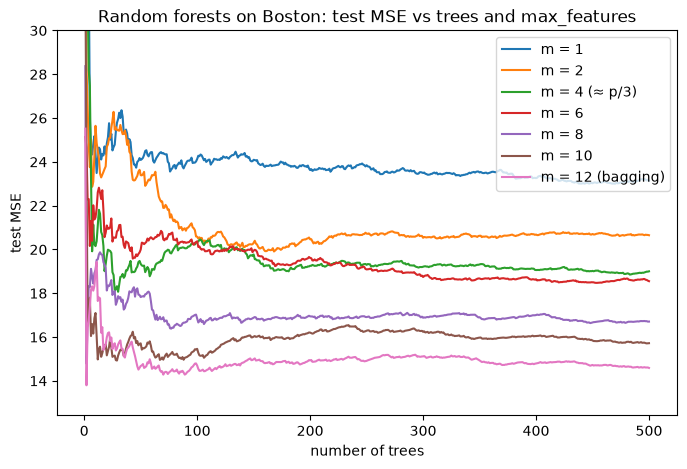

max_features
1     23.138
2     20.650
4     19.001
6     18.552
8     16.706
10    15.719
12    14.589
Name: test MSE with 500 trees, dtype: float64

In [2]:
# Exercise 7
Boston = load_data("Boston")
Xb, yb = Boston.drop(columns="medv"), Boston["medv"]
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.3, random_state=0)
p = Xb.shape[1]

n_trees = 500
curves = {}
for m in [1, 2, 4, 6, 8, 10, p]:
    rf = RF(n_estimators=n_trees, max_features=m, random_state=0, n_jobs=-1).fit(Xb_tr, yb_tr)
    per_tree = np.array([t.predict(Xb_te.to_numpy()) for t in rf.estimators_])
    running = np.cumsum(per_tree, axis=0) / np.arange(1, n_trees + 1)[:, None]
    curves[m] = ((running - yb_te.to_numpy())**2).mean(axis=1)

fig, ax = plt.subplots(figsize=(8, 5))
for m, curve in curves.items():
    label = f"m = {m}" + (" (bagging)" if m == p else "") + (" (≈ p/3)" if m == 4 else "") + (" (≈ √p)" if m == 3 else "")
    ax.plot(np.arange(1, n_trees + 1), curve, label=label)
ax.set(xlabel="number of trees", ylabel="test MSE", title="Random forests on Boston: test MSE vs trees and max_features",
       ylim=(min(c.min() for c in curves.values()) * 0.9, 30))
ax.legend()
plt.show()
final = pd.Series({m: c[-1] for m, c in curves.items()}, name="test MSE with 500 trees")
final.index.name = "max_features"
final.round(3)

**Observations / conclusions**

For every value of `max_features` (m), the test MSE falls quickly over the first ~30–50 trees and is essentially flat after ~100–200 trees. More trees never hurt; they just stop helping.
On this 70/30 split of Boston, larger m does better: with 500 trees, test MSE is 23.1 at m = 1, 19.0 at m = 4 (≈ p/3), 16.7 at m = 8, and 14.6 for bagging (m = 12). The textbook's split favoured m ≈ 6, so the best m depends on the split. Here a few strong predictors (`lstat`, `rm`) dominate. Very small m often leaves them out of a split, which raises bias more than decorrelating the trees lowers variance.

---

## Exercise 8 · Applied

**Textbook: printed page 364**

In the lab, a classification tree was applied to the Carseats data set after converting Sales into a qualitative response variable. Now we will
seek to predict Sales using regression trees and related approaches,
treating the response as a quantitative variable.

### Exercise 8(a)

Split the data set into a training set and a test set.

In [3]:
# Exercise 8(a)
Carseats = load_data("Carseats")
Xc = pd.get_dummies(Carseats.drop(columns="Sales"), drop_first=True, dtype=float)
yc = Carseats["Sales"]
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.5, random_state=0)
print(Xc_tr.shape, Xc_te.shape)
print(list(Xc.columns))
mse_8 = {}

(200, 11) (200, 11)
['CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'Age', 'Education', 'ShelveLoc_Good', 'ShelveLoc_Medium', 'Urban_Yes', 'US_Yes']


### Exercise 8(b)

Fit a regression tree to the training set. Plot the tree, and interpret the results. What test MSE do you obtain?

Unpruned tree: 200 leaves, depth 16, test MSE = 5.953


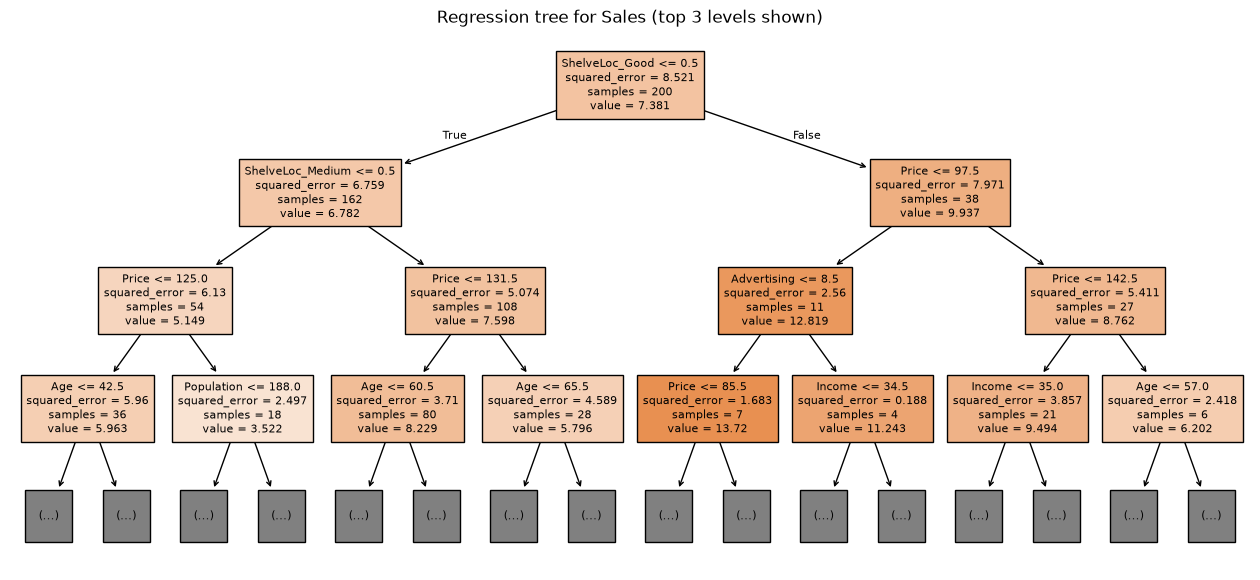

In [4]:
# Exercise 8(b)
reg_tree = DTR(random_state=0).fit(Xc_tr, yc_tr)
mse_8["Full regression tree"] = mean_squared_error(yc_te, reg_tree.predict(Xc_te))
print(f"Unpruned tree: {reg_tree.get_n_leaves()} leaves, depth {reg_tree.get_depth()}, "
      f"test MSE = {mse_8['Full regression tree']:.3f}")

# The full tree is far too large to read; plot its top 3 levels.
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(reg_tree, max_depth=3, feature_names=list(Xc.columns), filled=True, fontsize=8, ax=ax)
ax.set_title("Regression tree for Sales (top 3 levels shown)")
plt.show()

### Exercise 8(c)

Use cross-validation in order to determine the optimal level of
tree complexity. Does pruning the tree improve the test MSE?

CV-chosen alpha = 0.1815: 12 leaves, test MSE = 5.132


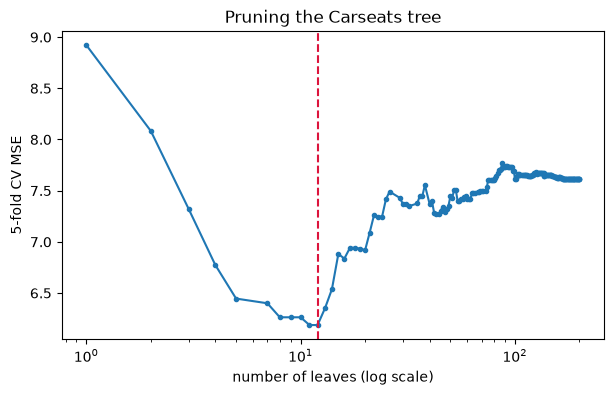

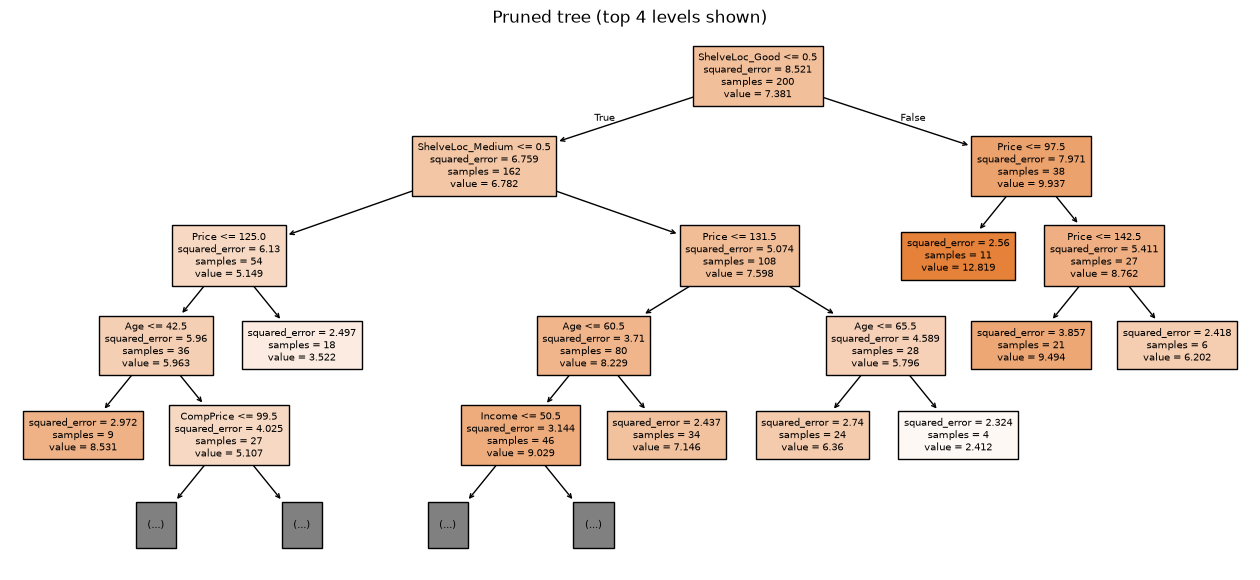

In [5]:
# Exercise 8(c)
kf = KFold(5, shuffle=True, random_state=10)
grid_8, path_8 = tree_cv_by_alpha(DTR, Xc_tr, yc_tr, kf, "neg_mean_squared_error")
pruned = grid_8.best_estimator_
mse_8["Pruned tree (CV)"] = mean_squared_error(yc_te, pruned.predict(Xc_te))
print(f"CV-chosen alpha = {grid_8.best_params_['ccp_alpha']:.4f}: {pruned.get_n_leaves()} leaves, "
      f"test MSE = {mse_8['Pruned tree (CV)']:.3f}")

leaves = [DTR(random_state=0, ccp_alpha=a).fit(Xc_tr, yc_tr).get_n_leaves() for a in path_8.ccp_alphas]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(leaves, -grid_8.cv_results_["mean_test_score"], marker="o", ms=3)
ax.axvline(pruned.get_n_leaves(), color="crimson", ls="--")
ax.set(xscale="log", xlabel="number of leaves (log scale)", ylabel="5-fold CV MSE", title="Pruning the Carseats tree")
plt.show()

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(pruned, feature_names=list(Xc.columns), filled=True, fontsize=7, ax=ax, max_depth=4)
ax.set_title("Pruned tree (top 4 levels shown)")
plt.show()

### Exercise 8(d)

Use the bagging approach in order to analyze this data. What
test MSE do you obtain? Use the feature_importance_ values to
determine which variables are most important.

In [6]:
# Exercise 8(d)
bag = RF(n_estimators=500, max_features=Xc.shape[1], random_state=0, n_jobs=-1).fit(Xc_tr, yc_tr)
mse_8["Bagging"] = mean_squared_error(yc_te, bag.predict(Xc_te))
print(f"Bagging test MSE = {mse_8['Bagging']:.3f}")
pd.Series(bag.feature_importances_, index=Xc.columns, name="importance").sort_values(ascending=False).round(4).to_frame()

Bagging test MSE = 2.673


,importance
Price,0.3326
ShelveLoc_Good,0.1533
Age,0.1153
CompPrice,0.0920
ShelveLoc_Medium,0.0767
Income,0.0660
Advertising,0.0630
Population,0.0557
Education,0.0324
US_Yes,0.0071


### Exercise 8(e)

Use random forests to analyze this data. What test MSE do
you obtain? Use the feature_importance_ values to determine
which variables are most important. Describe the effect of m, the
number of variables considered at each split, on the error rate
obtained.

m
1     4.022
2     3.328
3     2.975
4     2.842
5     2.708
6     2.600
7     2.604
8     2.616
9     2.630
10    2.659
11    2.673


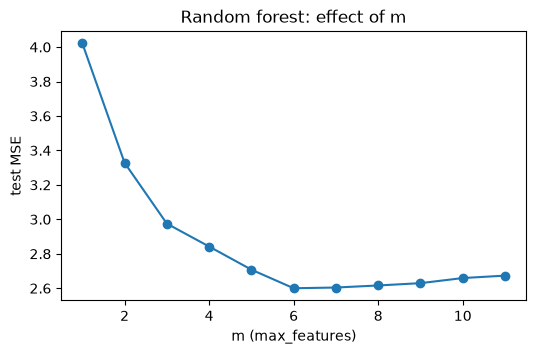

,importance (m=4)
Price,0.2806
ShelveLoc_Good,0.1299
Age,0.1235
CompPrice,0.0912
Income,0.0874
Population,0.0843
Advertising,0.0736
ShelveLoc_Medium,0.0600
Education,0.0463
US_Yes,0.0138


In [7]:
# Exercise 8(e)
rf_mse = {}
for m in range(1, Xc.shape[1] + 1):
    rf_m = RF(n_estimators=500, max_features=m, random_state=0, n_jobs=-1).fit(Xc_tr, yc_tr)
    rf_mse[m] = mean_squared_error(yc_te, rf_m.predict(Xc_te))
rf_mse = pd.Series(rf_mse, name="test MSE")
rf_mse.index.name = "m"
print(rf_mse.round(3).to_string())

m_rf = 4  # ≈ p/3, the usual default for regression forests
rf8 = RF(n_estimators=500, max_features=m_rf, random_state=0, n_jobs=-1).fit(Xc_tr, yc_tr)
mse_8[f"Random forest (m={m_rf})"] = mean_squared_error(yc_te, rf8.predict(Xc_te))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(rf_mse.index, rf_mse.values, marker="o")
ax.set(xlabel="m (max_features)", ylabel="test MSE", title="Random forest: effect of m")
plt.show()
pd.Series(rf8.feature_importances_, index=Xc.columns, name="importance (m=4)").sort_values(ascending=False).round(4).to_frame()

### Exercise 8(f)

Now analyze the data using BART, and report your results.

In [8]:
# Exercise 8(f)
bart = BART(random_state=0, burnin=5, ndraw=15).fit(Xc_tr.to_numpy(), yc_tr.to_numpy())
mse_8["BART"] = mean_squared_error(yc_te, bart.predict(Xc_te.to_numpy()))
print(f"BART test MSE = {mse_8['BART']:.3f}")
inclusion = pd.Series(bart.variable_inclusion_.mean(0), index=Xc.columns, name="mean # splits using variable")
display(inclusion.sort_values(ascending=False).round(2).to_frame())
pd.Series(mse_8, name="test MSE").round(3).to_frame()

BART test MSE = 1.561


,mean # splits using variable
Price,36.33
ShelveLoc_Good,33.40
CompPrice,29.67
US_Yes,29.27
ShelveLoc_Medium,27.67
Advertising,26.67
Age,26.33
Population,25.13
Urban_Yes,24.07
Income,23.87


,test MSE
Full regression tree,5.953
Pruned tree (CV),5.132
Bagging,2.673
Random forest (m=4),2.842
BART,1.561


**Observations / conclusions**

| method | test MSE |
|---|---|
| Unpruned regression tree (200 leaves) | 5.95 |
| CV-pruned tree (12 leaves) | 5.13 |
| Bagging (500 trees) | 2.67 |
| Random forest, m = 4 | 2.84 (best m = 6: 2.60) |
| BART | **1.56** |

- **(b)** The first splits are on `ShelveLoc` (Good vs not) and `Price`. Good shelf placement and low prices mean higher sales. The unpruned tree badly overfits (test MSE 5.95).
- **(c)** Cost-complexity pruning with 5-fold CV keeps 12 leaves and *does* improve test MSE (5.13).
- **(d, e)** Averaging many trees roughly halves the error. `Price`, `ShelveLoc_Good`, `Age` and `CompPrice` are the most important variables in both bagging and the random forest. Test MSE falls steeply from m = 1 (4.02) to m ≈ 5–6 (2.60) and then rises slightly toward the bagging value (2.67) at m = 11. Moderate decorrelation helps a little.
- **(f)** BART does best by a clear margin (1.56). Its relationship between `Sales` and the predictors is close to additive and partly linear, which BART's sum of small trees captures well. BART's variable-inclusion counts are flatter than tree importances, but `Price` and `ShelveLoc_Good` still come first.

---

## Exercise 9 · Applied

**Textbook: printed page 365**

This problem involves the OJ data set which is part of the ISLP
package.

### Exercise 9(a)

Create a training set containing a random sample of 800 observations, and a test set containing the remaining observations.

In [9]:
# Exercise 9(a)
OJ = load_data("OJ")
Xo = pd.get_dummies(OJ.drop(columns="Purchase"), drop_first=True, dtype=float)
yo = OJ["Purchase"]
Xo_tr, Xo_te, yo_tr, yo_te = train_test_split(Xo, yo, train_size=800, random_state=1)
print(Xo_tr.shape, Xo_te.shape)

(800, 17) (270, 17)


### Exercise 9(b)

Fit a tree to the training data, with Purchase as the response
and the other variables as predictors. What is the training error
rate?

In [10]:
# Exercise 9(b)
# sklearn grows trees until leaves are pure. To get a tree comparable to R's tree() default,
# stop splitting when a node has fewer than 10 observations or the improvement is tiny.
oj_tree = DTC(criterion="entropy", min_samples_split=10, min_samples_leaf=5,
              min_impurity_decrease=0.005, random_state=0).fit(Xo_tr, yo_tr)
train_err_tree = np.mean(oj_tree.predict(Xo_tr) != yo_tr)
print(f"Training error rate: {train_err_tree:.4f}")

Training error rate: 0.1400


### Exercise 9(c)

Create a plot of the tree, and interpret the results. How many
terminal nodes does the tree have?

Terminal nodes: 20, depth: 7


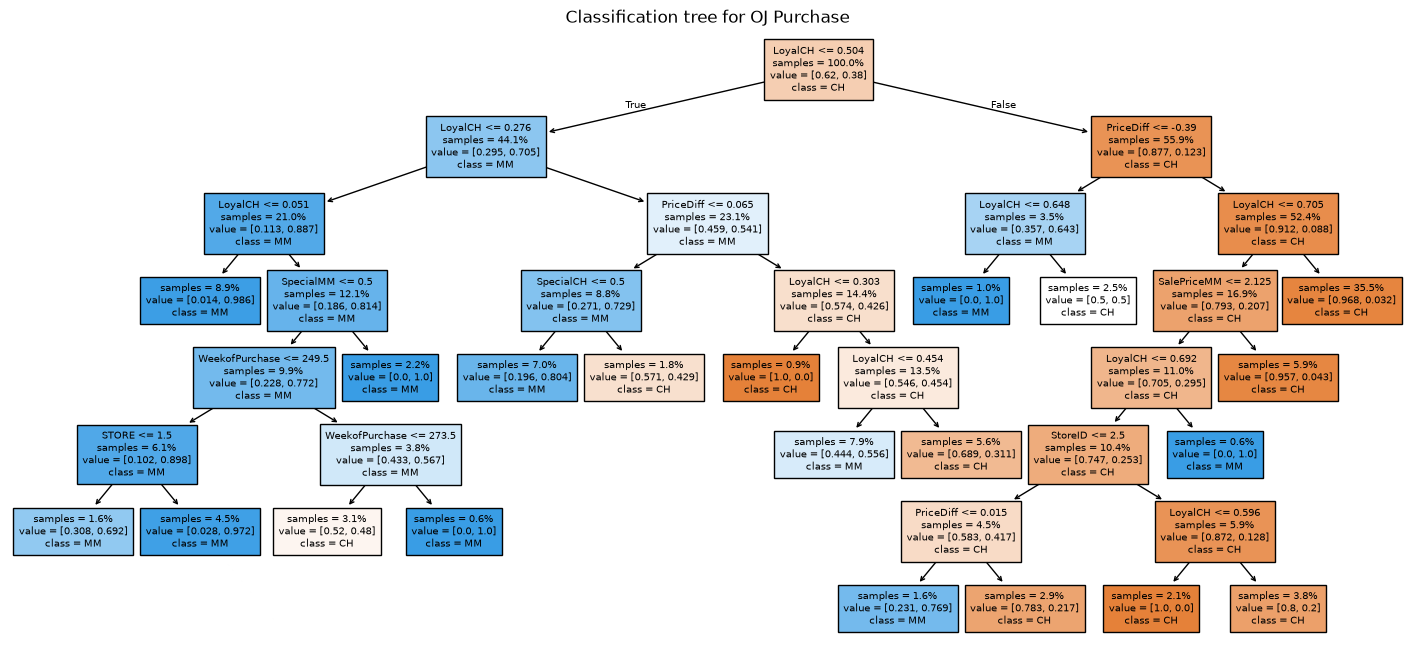

In [11]:
# Exercise 9(c)
print(f"Terminal nodes: {oj_tree.get_n_leaves()}, depth: {oj_tree.get_depth()}")
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(oj_tree, feature_names=list(Xo.columns), class_names=list(oj_tree.classes_), filled=True,
          fontsize=7, ax=ax, impurity=False, proportion=True)
ax.set_title("Classification tree for OJ Purchase")
plt.show()

### Exercise 9(d)

Use the export_tree() function to produce a text summary of
the fitted tree. Pick one of the terminal nodes, and interpret the
information displayed.

In [12]:
# Exercise 9(d)
print(export_text(oj_tree, feature_names=list(Xo.columns), show_weights=True, decimals=3))

|--- LoyalCH <= 0.504
|   |--- LoyalCH <= 0.276
|   |   |--- LoyalCH <= 0.051
|   |   |   |--- weights: [1.000, 70.000] class: MM
|   |   |--- LoyalCH >  0.051
|   |   |   |--- SpecialMM <= 0.500
|   |   |   |   |--- WeekofPurchase <= 249.500
|   |   |   |   |   |--- STORE <= 1.500
|   |   |   |   |   |   |--- weights: [4.000, 9.000] class: MM
|   |   |   |   |   |--- STORE >  1.500
|   |   |   |   |   |   |--- weights: [1.000, 35.000] class: MM
|   |   |   |   |--- WeekofPurchase >  249.500
|   |   |   |   |   |--- WeekofPurchase <= 273.500
|   |   |   |   |   |   |--- weights: [13.000, 12.000] class: CH
|   |   |   |   |   |--- WeekofPurchase >  273.500
|   |   |   |   |   |   |--- weights: [0.000, 5.000] class: MM
|   |   |   |--- SpecialMM >  0.500
|   |   |   |   |--- weights: [0.000, 18.000] class: MM
|   |--- LoyalCH >  0.276
|   |   |--- PriceDiff <= 0.065
|   |   |   |--- SpecialCH <= 0.500
|   |   |   |   |--- weights: [11.000, 45.000] class: MM
|   |   |   |--- SpecialCH >  

### Exercise 9(e)

Predict the response on the test data, and produce a confusion
matrix comparing the test labels to the predicted test labels.
What is the test error rate?

In [13]:
# Exercise 9(e)
pred_tree = oj_tree.predict(Xo_te)
display(confusion_table(pred_tree, yo_te))
test_err_tree = np.mean(pred_tree != yo_te)
print(f"Test error rate: {test_err_tree:.4f}")

Truth,CH,MM
Predicted,,
CH,137,32
MM,20,81


Test error rate: 0.1926


### Exercise 9(f)

Use cross-validation on the training set in order to determine
the optimal tree size.

In [14]:
# Exercise 9(f)
# Cross-validate over the cost-complexity pruning path of a fully grown tree.
kf_oj = KFold(10, shuffle=True, random_state=1)
full_oj = DTC(criterion="entropy", random_state=0).fit(Xo_tr, yo_tr)
alphas_oj = full_oj.cost_complexity_pruning_path(Xo_tr, yo_tr).ccp_alphas
grid_oj = GridSearchCV(DTC(criterion="entropy", random_state=0), {"ccp_alpha": alphas_oj},
                       cv=kf_oj, scoring="accuracy").fit(Xo_tr, yo_tr)
sizes = np.array([DTC(criterion="entropy", random_state=0, ccp_alpha=a).fit(Xo_tr, yo_tr).get_n_leaves()
                  for a in alphas_oj])
cv_err = 1 - grid_oj.cv_results_["mean_test_score"]
size_table = (pd.DataFrame({"tree size": sizes, "CV error": cv_err})
              .groupby("tree size")["CV error"].min())
print(f"Full tree has {full_oj.get_n_leaves()} leaves")
size_table.round(4).to_frame().T

Full tree has 157 leaves


tree size,1,2,3,4,5,6,7,8,9,11,...,128,132,139,142,143,145,147,150,153,157
CV error,0.3037,0.2138,0.2125,0.2012,0.205,0.2,0.2,0.2037,0.2025,0.2025,...,0.2263,0.2275,0.2275,0.2275,0.2275,0.2275,0.2275,0.2275,0.2275,0.2275


### Exercise 9(g)

Produce a plot with tree size on the x-axis and cross-validated
classification error rate on the y-axis.

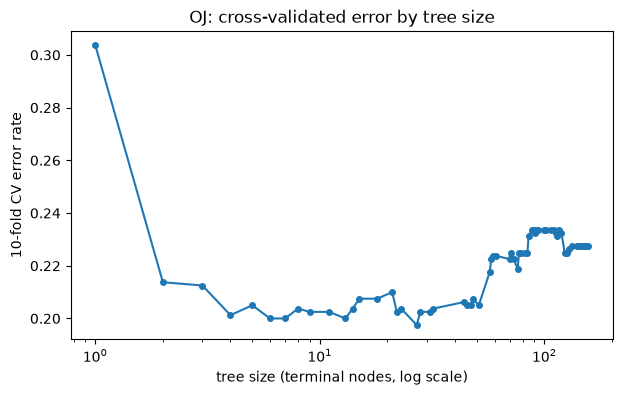

In [15]:
# Exercise 9(g)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(size_table.index, size_table.values, marker="o", ms=4)
ax.set(xscale="log", xlabel="tree size (terminal nodes, log scale)", ylabel="10-fold CV error rate",
       title="OJ: cross-validated error by tree size")
plt.show()

### Exercise 9(h)

Which tree size corresponds to the lowest cross-validated classification error rate?

In [16]:
# Exercise 9(h)
best_size = int(size_table.idxmin())
print(f"Lowest CV error {size_table.min():.4f} at tree size {best_size}")
print("Sizes within 0.5 percentage points of the minimum:",
      list(size_table[size_table <= size_table.min() + 0.005].index))

Lowest CV error 0.1975 at tree size 27
Sizes within 0.5 percentage points of the minimum: [4, 6, 7, 9, 11, 13, 27]


### Exercise 9(i)

Produce a pruned tree corresponding to the optimal tree size
obtained using cross-validation. If cross-validation does not lead
to selection of a pruned tree, then create a pruned tree with five
terminal nodes.

Pruned tree: 27 terminal nodes


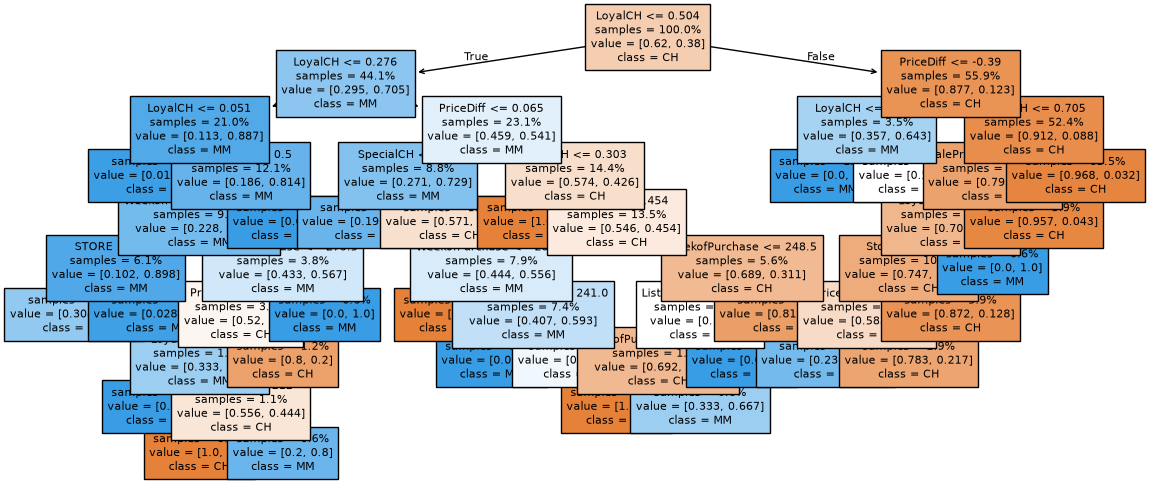

In [17]:
# Exercise 9(i)
alpha_best = alphas_oj[np.argmin(cv_err)]
pruned_oj = DTC(criterion="entropy", random_state=0, ccp_alpha=alpha_best).fit(Xo_tr, yo_tr)
if pruned_oj.get_n_leaves() == full_oj.get_n_leaves():
    # CV did not prune: fall back to a 5-leaf tree as the exercise suggests.
    pruned_oj = DTC(criterion="entropy", random_state=0, max_leaf_nodes=5).fit(Xo_tr, yo_tr)
print(f"Pruned tree: {pruned_oj.get_n_leaves()} terminal nodes")
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(pruned_oj, feature_names=list(Xo.columns), class_names=list(pruned_oj.classes_), filled=True,
          fontsize=8, ax=ax, impurity=False, proportion=True)
plt.show()

### Exercise 9(j)

Compare the training error rates between the pruned and unpruned trees. Which is higher?

In [18]:
# Exercise 9(j)
err_tbl = pd.DataFrame({
    "training error": [np.mean(m.predict(Xo_tr) != yo_tr) for m in (full_oj, oj_tree, pruned_oj)],
    "test error": [np.mean(m.predict(Xo_te) != yo_te) for m in (full_oj, oj_tree, pruned_oj)],
    "leaves": [m.get_n_leaves() for m in (full_oj, oj_tree, pruned_oj)],
}, index=["Fully grown (unpruned)", "Tree from (b)", "CV-pruned"])
err_tbl[["training error", "leaves"]].round(4)

,training error,leaves
Fully grown (unpruned),0.010,157
Tree from (b),0.140,20
CV-pruned,0.115,27


### Exercise 9(k)

Compare the test error rates between the pruned and unpruned
trees. Which is higher?

In [19]:
# Exercise 9(k)
err_tbl[["test error", "leaves"]].round(4)

,test error,leaves
Fully grown (unpruned),0.2296,157
Tree from (b),0.1926,20
CV-pruned,0.2000,27


**Observations / conclusions**

- **(b, c)** A tree stopped at a minimum node size (similar to R's `tree()` defaults) has **20 terminal nodes** and a **training error of 14.0%**. Nearly all the upper splits are on `LoyalCH`, customer brand loyalty to Citrus Hill. It is by far the most important variable, followed by `PriceDiff` and the specials/discounts.
- **(d)** Example terminal node: `LoyalCH ≤ 0.051` → weights [1, 70], class **MM**. Of the 71 training customers with almost no loyalty to CH, 70 bought Minute Maid. This leaf is very pure (98.6% MM).
- **(e)** Test confusion matrix: 137 + 81 correct, 32 + 20 wrong, so the **test error rate is 19.3%**.
- **(f–h)** 10-fold CV over the pruning path: error drops from 30.4% (1 leaf) to about 20% by 4 leaves and is then flat. The **minimum is 19.75% at 27 leaves**, but sizes 4–13 are all within 0.5 percentage points. The fully grown tree (157 leaves) has CV error 22.8%.
- **(i–k)** The CV-pruned tree has 27 leaves. Its *training* error (11.5%) is higher than the unpruned tree's (1.0%), as expected. Its *test* error (20.0%) is **lower** than the unpruned tree's (23.0%). Pruning trades a worse fit to the training data for better generalisation.

---

## Exercise 10 · Applied

**Textbook: printed page 366**

We now use boosting to predict Salary in the Hitters data set.

### Exercise 10(a)

Remove the observations for whom the salary information is
unknown, and then log-transform the salaries.

In [20]:
# Exercise 10(a)
Hitters = load_data("Hitters").dropna(subset=["Salary"])
Hitters["logSalary"] = np.log(Hitters["Salary"])
print(Hitters.shape)

(263, 21)


### Exercise 10(b)

Create a training set consisting of the first 200 observations, and
a test set consisting of the remaining observations.

In [21]:
# Exercise 10(b)
Xh = pd.get_dummies(Hitters.drop(columns=["Salary", "logSalary"]), drop_first=True, dtype=float)
yh = Hitters["logSalary"]
Xh_tr, Xh_te, yh_tr, yh_te = Xh.iloc[:200], Xh.iloc[200:], yh.iloc[:200], yh.iloc[200:]
print(Xh_tr.shape, Xh_te.shape)

(200, 19) (63, 19)


### Exercise 10(c)

Perform boosting on the training set with 1,000 trees for a range
of values of the shrinkage parameter λ. Produce a plot with
different shrinkage values on the x-axis and the corresponding
training set MSE on the y-axis.

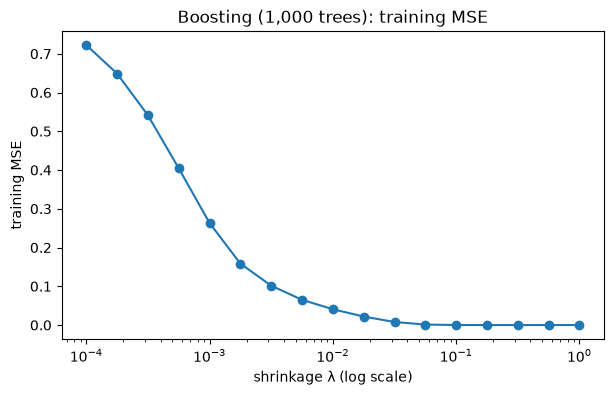

In [22]:
# Exercise 10(c)
shrinkages = np.logspace(-4, 0, 17)
train_mse_h, test_mse_h = {}, {}
for lam in shrinkages:
    gb = GBR(n_estimators=1000, learning_rate=lam, max_depth=2, random_state=0).fit(Xh_tr, yh_tr)
    train_mse_h[lam] = mean_squared_error(yh_tr, gb.predict(Xh_tr))
    test_mse_h[lam] = mean_squared_error(yh_te, gb.predict(Xh_te))
train_mse_h, test_mse_h = pd.Series(train_mse_h), pd.Series(test_mse_h)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(train_mse_h.index, train_mse_h.values, marker="o")
ax.set(xscale="log", xlabel="shrinkage λ (log scale)", ylabel="training MSE", title="Boosting (1,000 trees): training MSE")
plt.show()

### Exercise 10(d)

Produce a plot with different shrinkage values on the x-axis and
the corresponding test set MSE on the y-axis.

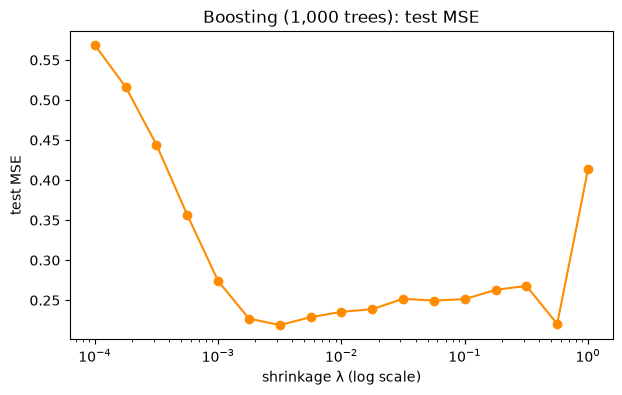

Lowest test MSE 0.2190 at λ = 0.0032


In [23]:
# Exercise 10(d)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(test_mse_h.index, test_mse_h.values, marker="o", color="darkorange")
ax.set(xscale="log", xlabel="shrinkage λ (log scale)", ylabel="test MSE", title="Boosting (1,000 trees): test MSE")
plt.show()
best_lam = test_mse_h.idxmin()
print(f"Lowest test MSE {test_mse_h.min():.4f} at λ = {best_lam:.4f}")

### Exercise 10(e)

Compare the test MSE of boosting to the test MSE that results
from applying two of the regression approaches seen in
Chapters 3 and 6.

In [24]:
# Exercise 10(e)
mse_10 = {"Boosting (best λ)": test_mse_h.min()}
mse_10["Least squares (Ch. 3)"] = mean_squared_error(yh_te, LinearRegression().fit(Xh_tr, yh_tr).predict(Xh_te))
lasso_h = make_pipeline(StandardScaler(), LassoCV(cv=KFold(10, shuffle=True, random_state=0), max_iter=100_000)).fit(Xh_tr, yh_tr)
mse_10["Lasso (Ch. 6)"] = mean_squared_error(yh_te, lasso_h.predict(Xh_te))
pd.Series(mse_10, name="test MSE (log salary)").round(4).to_frame()

,test MSE (log salary)
Boosting (best λ),0.2190
Least squares (Ch. 3),0.4918
Lasso (Ch. 6),0.4713


### Exercise 10(f)

Which variables appear to be the most important predictors in
the boosted model?

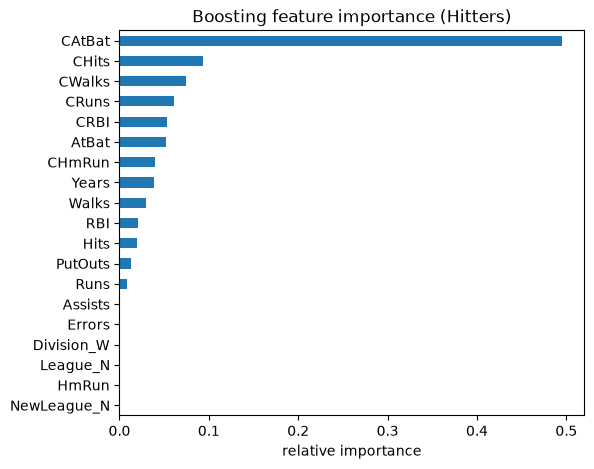

CAtBat    0.4955
CHits     0.0937
CWalks    0.0745
CRuns     0.0606
CRBI      0.0532
AtBat     0.0517
dtype: float64

In [25]:
# Exercise 10(f)
gb_best = GBR(n_estimators=1000, learning_rate=best_lam, max_depth=2, random_state=0).fit(Xh_tr, yh_tr)
imp = pd.Series(gb_best.feature_importances_, index=Xh.columns).sort_values()
fig, ax = plt.subplots(figsize=(6, 5))
imp.plot.barh(ax=ax)
ax.set(title="Boosting feature importance (Hitters)", xlabel="relative importance")
plt.show()
imp.sort_values(ascending=False).head(6).round(4)

### Exercise 10(g)

Now apply bagging to the training set. What is the test set MSE
for this approach?

In [26]:
# Exercise 10(g)
bag_h = RF(n_estimators=500, max_features=Xh.shape[1], random_state=0, n_jobs=-1).fit(Xh_tr, yh_tr)
mse_10["Bagging"] = mean_squared_error(yh_te, bag_h.predict(Xh_te))
print(f"Bagging test MSE = {mse_10['Bagging']:.4f}")
pd.Series(mse_10, name="test MSE (log salary)").sort_values().round(4).to_frame()

Bagging test MSE = 0.2309


,test MSE (log salary)
Boosting (best λ),0.2190
Bagging,0.2309
Lasso (Ch. 6),0.4713
Least squares (Ch. 3),0.4918


**Observations / conclusions**

263 players have a recorded salary; I used the first 200 for training and the remaining 63 for testing, with log salary as the response.
- **(c)** Training MSE decreases steadily as λ grows. With 1,000 trees and λ near 1, the model almost interpolates the training data.
- **(d)** Test MSE is U-shaped in λ. It is high for tiny λ (1,000 trees aren't enough) and rises again for λ ≳ 0.1 (overfitting). The minimum is about **0.219 at λ ≈ 0.003**.
- **(e)** Boosting (0.219) more than halves the test MSE of least squares (0.492) and the lasso (0.471). Salary depends on career length in a strongly nonlinear, threshold-like way, which linear models can't capture.
- **(f)** Career at-bats `CAtBat` dominates (≈ 50% of importance), followed by other career totals (`CHits`, `CWalks`, `CRuns`, `CRBI`). Seniority and track record drive salary.
- **(g)** Bagging gives a test MSE of 0.231, close to boosting and also far better than the linear models.

---

## Exercise 11 · Applied

**Textbook: printed page 366**

This question uses the Caravan data set.

### Exercise 11(a)

Create a training set consisting of the first 1,000 observations,
and a test set consisting of the remaining observations.

In [27]:
# Exercise 11(a)
Caravan = load_data("Caravan")
Xv = Caravan.drop(columns="Purchase")
yv = (Caravan["Purchase"] == "Yes").astype(int)
Xv_tr, Xv_te, yv_tr, yv_te = Xv.iloc[:1000], Xv.iloc[1000:], yv.iloc[:1000], yv.iloc[1000:]
print(Xv_tr.shape, Xv_te.shape, f"purchase rate (test) = {yv_te.mean():.4f}")

(1000, 85) (4822, 85) purchase rate (test) = 0.0599


### Exercise 11(b)

Fit a boosting model to the training set with Purchase as the
response and the other variables as predictors. Use 1,000 trees,
and a shrinkage value of 0.01. Which predictors appear to be
the most important?

In [28]:
# Exercise 11(b)
gb_car = GBC(n_estimators=1000, learning_rate=0.01, max_depth=2, random_state=0).fit(Xv_tr, yv_tr)
pd.Series(gb_car.feature_importances_, index=Xv.columns, name="importance").sort_values(ascending=False).head(10).round(4).to_frame()

,importance
MOSTYPE,0.1073
PPERSAUT,0.1069
MKOOPKLA,0.0562
MGODGE,0.0534
ABRAND,0.0522
PPLEZIER,0.0463
MBERMIDD,0.0407
APLEZIER,0.0384
AMOTSCO,0.0330
MOPLHOOG,0.0317


### Exercise 11(c)

Use the boosting model to predict the response on the test data.
Predict that a person will make a purchase if the estimated probability of purchase is greater than 20 %. Form a confusion matrix. What fraction of the people predicted to make a purchase
do in fact make one? How does this compare with the results
obtained from applying KNN or logistic regression to this data
set?

In [29]:
# Exercise 11(c)
def precision_report(name, prob, threshold=0.2):
    pred = (prob > threshold).astype(int)
    tbl = confusion_table(pred, yv_te)
    n_pred = pred.sum()
    hit = ((pred == 1) & (yv_te == 1)).sum()
    return {"method": name, "predicted buyers": int(n_pred), "actual buyers among them": int(hit),
            "precision": hit / n_pred if n_pred else np.nan}, tbl

rows = []
row, tbl = precision_report("Boosting", gb_car.predict_proba(Xv_te)[:, 1])
print("Boosting confusion matrix (threshold 0.2):")
display(tbl)
rows.append(row)

logit = LogisticRegression(max_iter=5000).fit(StandardScaler().fit(Xv_tr).transform(Xv_tr), yv_tr)
sc = StandardScaler().fit(Xv_tr)
rows.append(precision_report("Logistic regression", logit.predict_proba(sc.transform(Xv_te))[:, 1])[0])
for k in [1, 3, 5]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(sc.transform(Xv_tr), yv_tr)
    rows.append(precision_report(f"KNN K={k}", knn.predict_proba(sc.transform(Xv_te))[:, 1])[0])
pd.DataFrame(rows).set_index("method").round(4)

Boosting confusion matrix (threshold 0.2):


Truth,0,1
Predicted,,
0,4368,251
1,165,38


,predicted buyers,actual buyers among them,precision
method,,,
Boosting,203,38,0.1872
Logistic regression,290,48,0.1655
KNN K=1,317,41,0.1293
KNN K=3,837,92,0.1099
KNN K=5,250,40,0.1600


**Observations / conclusions**

- **(b)** In the boosted model (1,000 trees, λ = 0.01), the most important predictors are `MOSTYPE` (customer subtype) and `PPERSAUT` (contribution to car policies), followed by `MKOOPKLA` (purchasing-power class), `MGODGE`, `ABRAND` (number of fire policies) and `PPLEZIER` (boat policies).
- **(c)** Using P(purchase) > 0.2, boosting flags 203 people, and **38 of them (18.7%) actually buy**. The base rate is 6.0%, so that is about three times better than contacting people at random. Logistic regression with the same 0.2 threshold reaches 16.6% (48 of 290), and KNN reaches 11–16% (K = 5 is best at 16.0%). Boosting gives the highest precision. Logistic regression finds a few more buyers in total, but at the cost of contacting more non-buyers.

---

## Exercise 12 · Applied

**Textbook: printed page 366**

Apply boosting, bagging, random forests, and BART to a data set
of your choice. Be sure to fit the models on a training set and to
evaluate their performance on a test set. How accurate are the results
compared to simple methods like linear or logistic regression? Which
of these approaches yields the best performance?

In [30]:
# Exercise 12: predict mpg in the Auto data.
Auto = load_data("Auto")
Xa = pd.get_dummies(Auto.drop(columns="mpg").astype({"origin": "category"}), drop_first=True, dtype=float)
ya = Auto["mpg"]
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=0.3, random_state=0)

models_12 = {
    "Linear regression": LinearRegression(),
    "Bagging": RF(n_estimators=500, max_features=None, random_state=0, n_jobs=-1),
    "Random forest (m = p/3)": RF(n_estimators=500, max_features=1/3, random_state=0, n_jobs=-1),
    "Boosting": GBR(n_estimators=1000, learning_rate=0.01, max_depth=3, random_state=0),
}
mse_12 = {name: mean_squared_error(ya_te, m.fit(Xa_tr, ya_tr).predict(Xa_te)) for name, m in models_12.items()}
bart_a = BART(random_state=0, burnin=5, ndraw=15).fit(Xa_tr.to_numpy(), ya_tr.to_numpy())
mse_12["BART"] = mean_squared_error(ya_te, bart_a.predict(Xa_te.to_numpy()))
res_12 = pd.DataFrame({"test MSE": mse_12})
res_12["test RMSE (mpg)"] = np.sqrt(res_12["test MSE"])
res_12.sort_values("test MSE").round(3)

,test MSE,test RMSE (mpg)
BART,8.138,2.853
Boosting,8.647,2.941
Bagging,8.714,2.952
Random forest (m = p/3),9.031,3.005
Linear regression,10.860,3.295


**Observations / conclusions**

I predicted `mpg` in the Auto data (392 cars, 70/30 split) from cylinders, displacement, horsepower, weight, acceleration, year and origin (as dummies).

| method | test MSE | RMSE (mpg) |
|---|---|---|
| BART | **8.14** | 2.85 |
| Boosting (1,000 trees, λ = 0.01, depth 3) | 8.65 | 2.94 |
| Bagging | 8.71 | 2.95 |
| Random forest (m = p/3) | 9.03 | 3.01 |
| Linear regression | 10.86 | 3.30 |

All four tree ensembles beat linear regression by about 17–25% in MSE. mpg depends nonlinearly on weight and horsepower, and model year interacts with the other variables. BART is best, with boosting and bagging close behind; differences of ~0.5 in MSE are within split-to-split noise on a test set this small (118 cars).